In [24]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project root
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

# Results directory
RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)
print("Results directory exists:", RESULTS_DIR.exists())

Project root: /home/scinolimits/robotics/image_processing_and_computer_vision/shortcut-learning-analysis
Results directory exists: True


In [25]:
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures directory:", FIGURES_DIR)

Figures directory: /home/scinolimits/robotics/image_processing_and_computer_vision/shortcut-learning-analysis/results/figures


In [26]:
accuracy_df = pd.read_csv(
    RESULTS_DIR / "cross_condition_accuracy.csv",
    index_col=0
)

stability_df = pd.read_csv(
    RESULTS_DIR / "prediction_stability.csv",
    index_col=0
)

intervention_df = pd.read_csv(
    RESULTS_DIR / "intervention_summary_results.csv"
)

per_colour_df = pd.read_csv(
    RESULTS_DIR / "per_colour_intervention_results.csv"
)

print("Cross-condition accuracy:")
display(accuracy_df)

print("Prediction stability:")
display(stability_df)

print("Controlled intervention summary:")
display(intervention_df)

print("Per-colour intervention results:")
display(per_colour_df.head())

Cross-condition accuracy:


,Test_100%,Test_90%,Test_70%,Test_10%
Train_100%,99.99,90.48,70.65,12.12
Train_90%,99.40,97.07,92.58,78.52
Train_70%,98.49,97.25,94.56,86.54
Train_10%,90.00,89.96,90.09,90.58


Prediction stability:


,Exact_Consistency,Pairwise_Agreement
Train_100%,7.73,43.526667
Train_90%,75.17,86.461667
Train_70%,85.64,92.266667
Train_10%,96.28,98.013333


Controlled intervention summary:


,training_strength,object_accuracy,cue_following_rate,mean_true_class_probability,mean_cue_class_probability,mismatched_cue_following_rate,prediction_consistency
0,100,11.976,92.956,12.191893,91.743614,92.174444,0.01
1,90,78.326,20.791,74.470750,20.510572,12.056667,41.98
2,70,86.349,15.199,83.968570,15.177485,5.944444,64.13
3,10,90.337,9.945,88.057175,9.968452,1.050000,91.16


Per-colour intervention results:


,training_strength,background_class,object_accuracy,cue_following_rate,mean_true_class_probability,mean_cue_class_probability,mismatched_cue_following_rate
0,100,0,10.04,99.93,10.031362,99.915924,99.933333
1,100,1,10.01,99.94,10.017411,99.875560,99.933333
2,100,2,10.09,99.87,10.182354,99.698490,99.855556
3,100,3,19.97,74.73,19.994505,74.681465,71.922222
4,100,4,10.01,99.98,10.108704,99.613350,99.977778


In [27]:
print("Column names:")
print(intervention_df.columns.tolist())

print("\nData types:")
print(intervention_df.dtypes)

print("\nFull intervention summary:")
display(intervention_df.to_string(index=False))

Column names:
['training_strength', 'object_accuracy', 'cue_following_rate', 'mean_true_class_probability', 'mean_cue_class_probability', 'mismatched_cue_following_rate', 'prediction_consistency']

Data types:
training_strength                  int64
object_accuracy                  float64
cue_following_rate               float64
mean_true_class_probability      float64
mean_cue_class_probability       float64
mismatched_cue_following_rate    float64
prediction_consistency           float64
dtype: object

Full intervention summary:


' training_strength  object_accuracy  cue_following_rate  mean_true_class_probability  mean_cue_class_probability  mismatched_cue_following_rate  prediction_consistency\n               100           11.976              92.956                    12.191893                   91.743614                      92.174444                    0.01\n                90           78.326              20.791                    74.470750                   20.510572                      12.056667                   41.98\n                70           86.349              15.199                    83.968570                   15.177485                       5.944444                   64.13\n                10           90.337               9.945                    88.057175                    9.968452                       1.050000                   91.16'

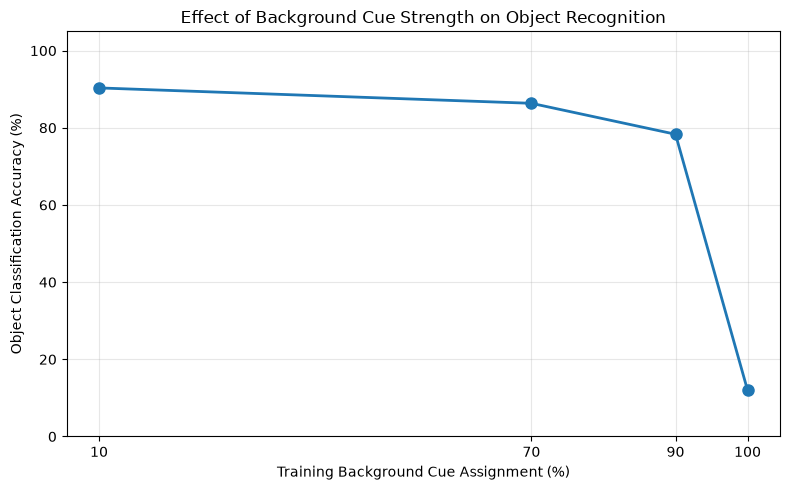

In [28]:
# Prepare data
plot_df = intervention_df.sort_values(
    by="training_strength",
    ascending=False
)

# Create figure
plt.figure(figsize=(8, 5))

plt.plot(
    plot_df["training_strength"],
    plot_df["object_accuracy"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Training Background Cue Assignment (%)")
plt.ylabel("Object Classification Accuracy (%)")
plt.title("Effect of Background Cue Strength on Object Recognition")

plt.xticks([10, 70, 90, 100])
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_1_object_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



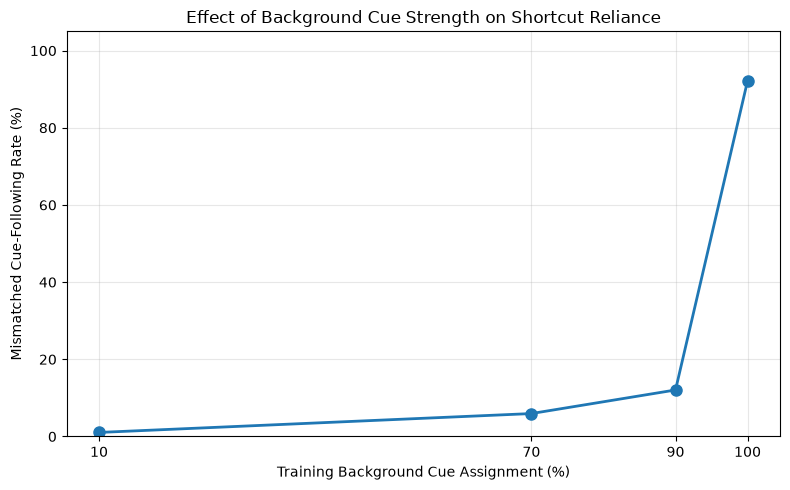

In [29]:
plot_df = intervention_df.sort_values(
    by="training_strength",
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_df["training_strength"],
    plot_df["mismatched_cue_following_rate"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Training Background Cue Assignment (%)")
plt.ylabel("Mismatched Cue-Following Rate (%)")
plt.title("Effect of Background Cue Strength on Shortcut Reliance")

plt.xticks([10, 70, 90, 100])
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_2_cue_following.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

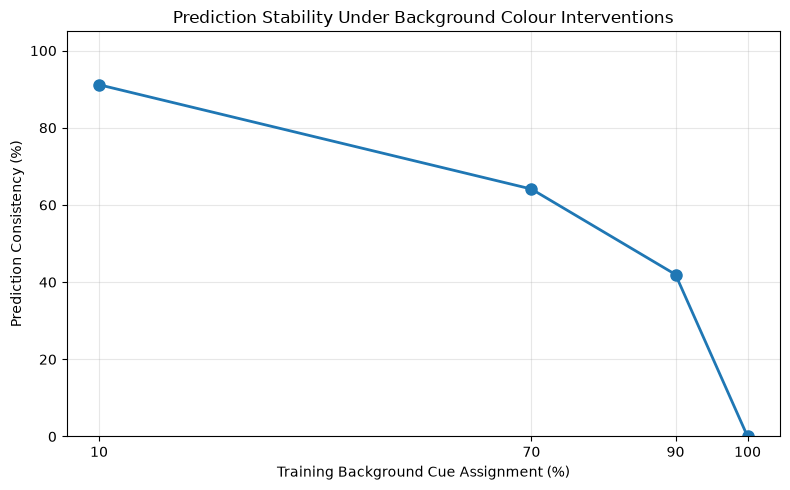

In [30]:
plot_df = intervention_df.sort_values(
    by="training_strength",
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_df["training_strength"],
    plot_df["prediction_consistency"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Training Background Cue Assignment (%)")
plt.ylabel("Prediction Consistency (%)")
plt.title("Prediction Stability Under Background Colour Interventions")

plt.xticks([10, 70, 90, 100])
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_3_prediction_consistency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# Create a pivot table:
# Rows = training cue strength
# Columns = background colour class
# Values = mismatched cue-following rate

heatmap_data = per_colour_df.pivot(
    index="training_strength",
    columns="background_class",
    values="mismatched_cue_following_rate"
)

# Sort training strengths
heatmap_data = heatmap_data.sort_index(ascending=False)

display(heatmap_data)

background_class,0,1,2,3,4,5,6,7,8,9
training_strength,,,,,,,,,,
100,99.933333,99.933333,99.855556,71.922222,99.977778,96.800000,99.811111,54.255556,100.000000,99.255556
90,10.500000,1.088889,22.388889,14.611111,19.844444,4.000000,36.255556,5.400000,1.844444,4.633333
70,9.211111,0.911111,11.055556,4.488889,8.188889,1.488889,18.022222,2.844444,1.044444,2.188889
10,1.522222,0.100000,1.655556,0.911111,1.344444,0.244444,3.600000,0.611111,0.144444,0.366667


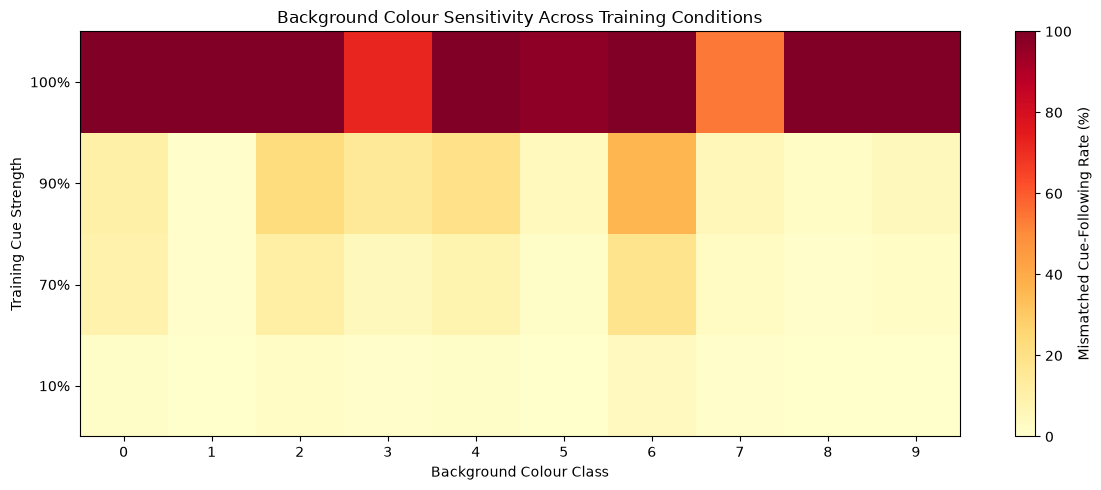

In [32]:
plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Mismatched Cue-Following Rate (%)")

plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns
)

plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=[f"{x}%" for x in heatmap_data.index]
)

plt.xlabel("Background Colour Class")
plt.ylabel("Training Cue Strength")
plt.title("Background Colour Sensitivity Across Training Conditions")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_4_colour_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
saved_figures = list(FIGURES_DIR.glob("*.png"))

for figure in saved_figures:
    print(figure.name, f"({figure.stat().st_size / 1024:.1f} KB)")

print(f"\nTotal figures saved: {len(saved_figures)}")


figure_4_colour_heatmap.png (125.2 KB)
figure_1_object_accuracy.png (120.9 KB)
figure_2_cue_following.png (115.9 KB)
figure_3_prediction_consistency.png (126.6 KB)

Total figures saved: 4
